In [6]:
import numpy as np
import time

size = 10_000_000
data = np.random.rand(size)

# --- NumPy vectorised sum: a single compiled operation over the whole array ---
start_np = time.time()
np_sum = np.sum(data)
end_np = time.time()

# --- Manual Python loop: ten million interpreted iterations ------------------
start_py = time.time()
manual_sum = 0
for val in data:
    manual_sum += val
end_py = time.time()

print(f"NumPy Sum : {np_sum:.2f} | Time: {end_np - start_np:.5f} sec")
print(f"Manual Sum: {manual_sum:.2f} | Time: {end_py - start_py:.5f} sec")
print()
print(f"NumPy is {(end_py - start_py) / (end_np - start_np):.0f}x faster on this machine.")

NumPy Sum : 5000435.80 | Time: 0.02113 sec
Manual Sum: 5000435.80 | Time: 4.62549 sec

NumPy is 219x faster on this machine.


In [7]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time

urls = [
    'https://techncruncher.blogspot.com/2025/01/top-10-ai-tools-that-will-transform.html',
    'https://techncruncher.blogspot.com/2023/12/limewire-ai-studio-review-2023-details.html',
    'https://techncruncher.blogspot.com/2023/01/top-10-ai-tools-in-2023-that-will-make.html',
    'https://techncruncher.blogspot.com/2022/11/top-10-ai-content-generator-writer.html',
    'https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html'
]

headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
articles = []

for url in urls:
    try:
        # Fetch the page content
        res = requests.get(url, headers=headers, timeout=10)
        res.raise_for_status()
        soup = BeautifulSoup(res.content, 'lxml')

        # Extract Title
        title = soup.find('h3', class_='post-title')
        title = title.get_text(strip=True) if title else soup.title.get_text(strip=True)

        # Extract Body Text
        content_div = soup.find('div', class_='post-body entry-content')
        if not content_div:
            print(f"[SKIP] No content block found: {url}")
            continue

        paragraphs = content_div.find_all('p')
        text = ' '.join(p.get_text(strip=True) for p in paragraphs)

        # Skip short articles for quality control
        if len(text) > 100:
            articles.append({'url': url, 'title': title, 'text': text})
        else:
            print(f"[SKIP] Too short: {url}")

        time.sleep(1)   # Be polite to the server
    except Exception as e:
        print(f"[ERROR] {url} -> {e}")

df = pd.DataFrame(articles)
print(f"\nScraped {len(df)} of {len(urls)} articles.")
df.head()

[ERROR] https://techncruncher.blogspot.com/2025/01/top-10-ai-tools-that-will-transform.html -> HTTPSConnectionPool(host='techncruncher.blogspot.com', port=443): Read timed out. (read timeout=10)
[ERROR] https://techncruncher.blogspot.com/2023/12/limewire-ai-studio-review-2023-details.html -> HTTPSConnectionPool(host='techncruncher.blogspot.com', port=443): Read timed out. (read timeout=10)
[SKIP] Too short: https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html

Scraped 2 of 5 articles.


,url,title,text
0,https://techncruncher.blogspot.com/2023/01/top...,Top 10 AI Tools in 2023 That Will Make Your Li...,"In this article, we explore the top 10 AI too..."
1,https://techncruncher.blogspot.com/2022/11/top...,Top 10 AI Content Generator & Writer Tools in ...,There are a number of different AI content ...


In [8]:
# Save the raw scrape immediately, so the rest of the lab works offline
# and so your results are reproducible even after the sites change.
if not df.empty:
    df.to_csv("articles_raw.csv", index=False)
    print("Saved articles_raw.csv")
else:
    # Fallback: load a previously saved scrape
    df = pd.read_csv("articles_raw.csv")
    print("Network scrape empty -- loaded the cached articles_raw.csv instead.")

print(df.shape)

Saved articles_raw.csv
(2, 3)


In [9]:
import spacy
import pandas as pd

# Loads the trained spaCy English model: tokenizer, POS tagger and NER
nlp = spacy.load("en_core_web_sm")

def extract_features(text):
    """Process text with spaCy and extract four linguistic features."""
    doc = nlp(text)
    return pd.Series({
        'num_tokens':    len(doc),                                   # tokens
        'num_sentences': len(list(doc.sents)),                       # sentences
        'num_entities':  len(doc.ents),                              # named entities
        'num_nouns':     len([t for t in doc if t.pos_ == 'NOUN'])   # nouns
    })

if not df.empty:
    features = df['text'].apply(extract_features)
    df = pd.concat([df, features], axis=1)

    # A simple non-spaCy feature for comparison
    df['title_length'] = df['title'].apply(len)

    print("Features extracted successfully.")
    display(df[['title', 'num_tokens', 'num_sentences', 'num_entities', 'num_nouns']].head())
else:
    print("No articles found for feature extraction.")


Features extracted successfully.


,title,num_tokens,num_sentences,num_entities,num_nouns
0,Top 10 AI Tools in 2023 That Will Make Your Li...,1480,52,39,331
1,Top 10 AI Content Generator & Writer Tools in ...,1319,63,89,271


In [10]:
# Inspect WHAT spaCy actually found, not just how many.
# Reading the entities is how you learn whether the feature is meaningful.

doc = nlp(df['text'].iloc[0][:1500])

print("First 15 named entities in article 1:\n")
for ent in list(doc.ents)[:15]:
    print(f"  {ent.text:<35} {ent.label_:<12} ({spacy.explain(ent.label_)})")

First 15 named entities in article 1:

  10                                  CARDINAL     (Numerals that do not fall under another type)
  AI                                  GPE          (Countries, cities, states)
  OpenAI Codex                        ORG          (Companies, agencies, institutions, etc.)
  Tabnine                             PERSON       (People, including fictional)
  Canva                               PERSON       (People, including fictional)
  Jasper AI                           PERSON       (People, including fictional)
  Surfer SEO                          WORK_OF_ART  (Titles of books, songs, etc.)
  AI                                  GPE          (Countries, cities, states)
  OpenAI                              GPE          (Countries, cities, states)


In [11]:
from textblob import TextBlob

def get_sentiment(text):
    """Polarity in [-1, 1]; subjectivity in [0, 1]."""
    blob = TextBlob(text)
    return pd.Series({
        'sentiment_polarity':     blob.sentiment.polarity,
        'sentiment_subjectivity': blob.sentiment.subjectivity
    })

if not df.empty:
    sentiment_features = df['text'].apply(get_sentiment)
    df = pd.concat([df, sentiment_features], axis=1)

    print("Sentiment features extracted successfully.\n")
    display(df[['title', 'sentiment_polarity', 'sentiment_subjectivity']])

Sentiment features extracted successfully.



,title,sentiment_polarity,sentiment_subjectivity
0,Top 10 AI Tools in 2023 That Will Make Your Li...,0.197417,0.436441
1,Top 10 AI Content Generator & Writer Tools in ...,0.214853,0.564907


In [12]:
# Persist the fully engineered table -- this is the Lab 02 deliverable.
df.to_csv("articles.csv", index=False)
print("Saved articles.csv with", df.shape[1], "columns:")
print(list(df.columns))

Saved articles.csv with 10 columns:
['url', 'title', 'text', 'num_tokens', 'num_sentences', 'num_entities', 'num_nouns', 'title_length', 'sentiment_polarity', 'sentiment_subjectivity']


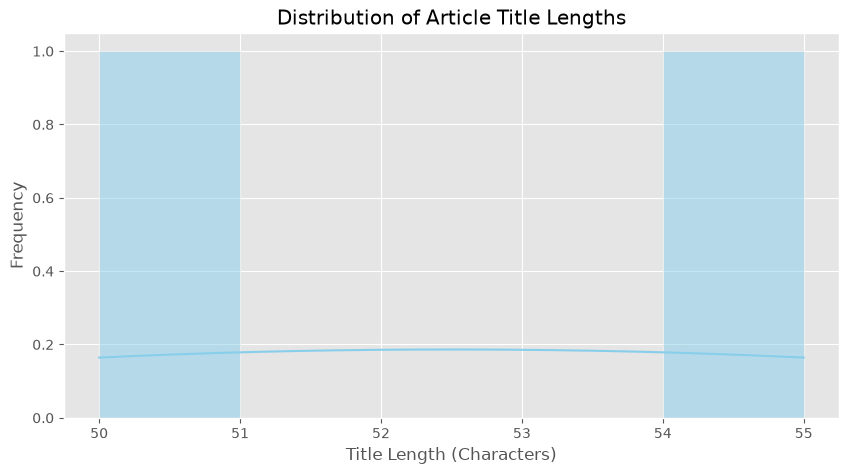

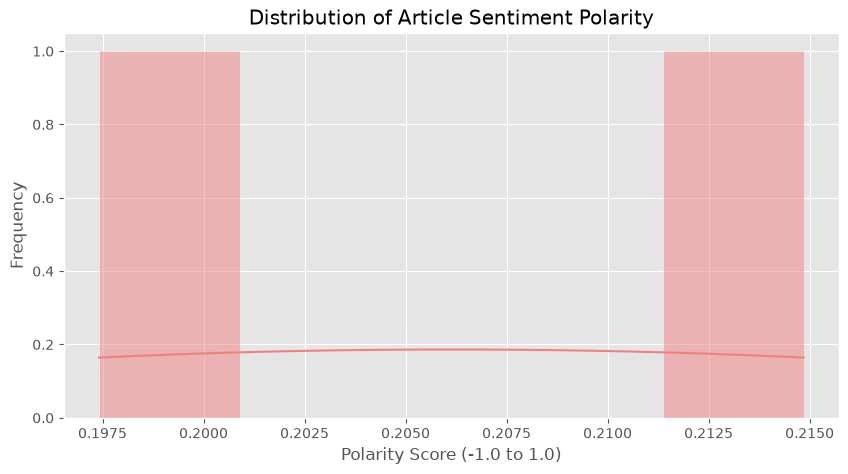

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

# 1. Title Length Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['title_length'], kde=True, bins=5, color='skyblue')
plt.title('Distribution of Article Title Lengths')
plt.xlabel('Title Length (Characters)')
plt.ylabel('Frequency')
plt.show()

# 2. Sentiment Polarity Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['sentiment_polarity'], kde=True, bins=5, color='lightcoral')
plt.title('Distribution of Article Sentiment Polarity')
plt.xlabel('Polarity Score (-1.0 to 1.0)')
plt.ylabel('Frequency')
plt.show()

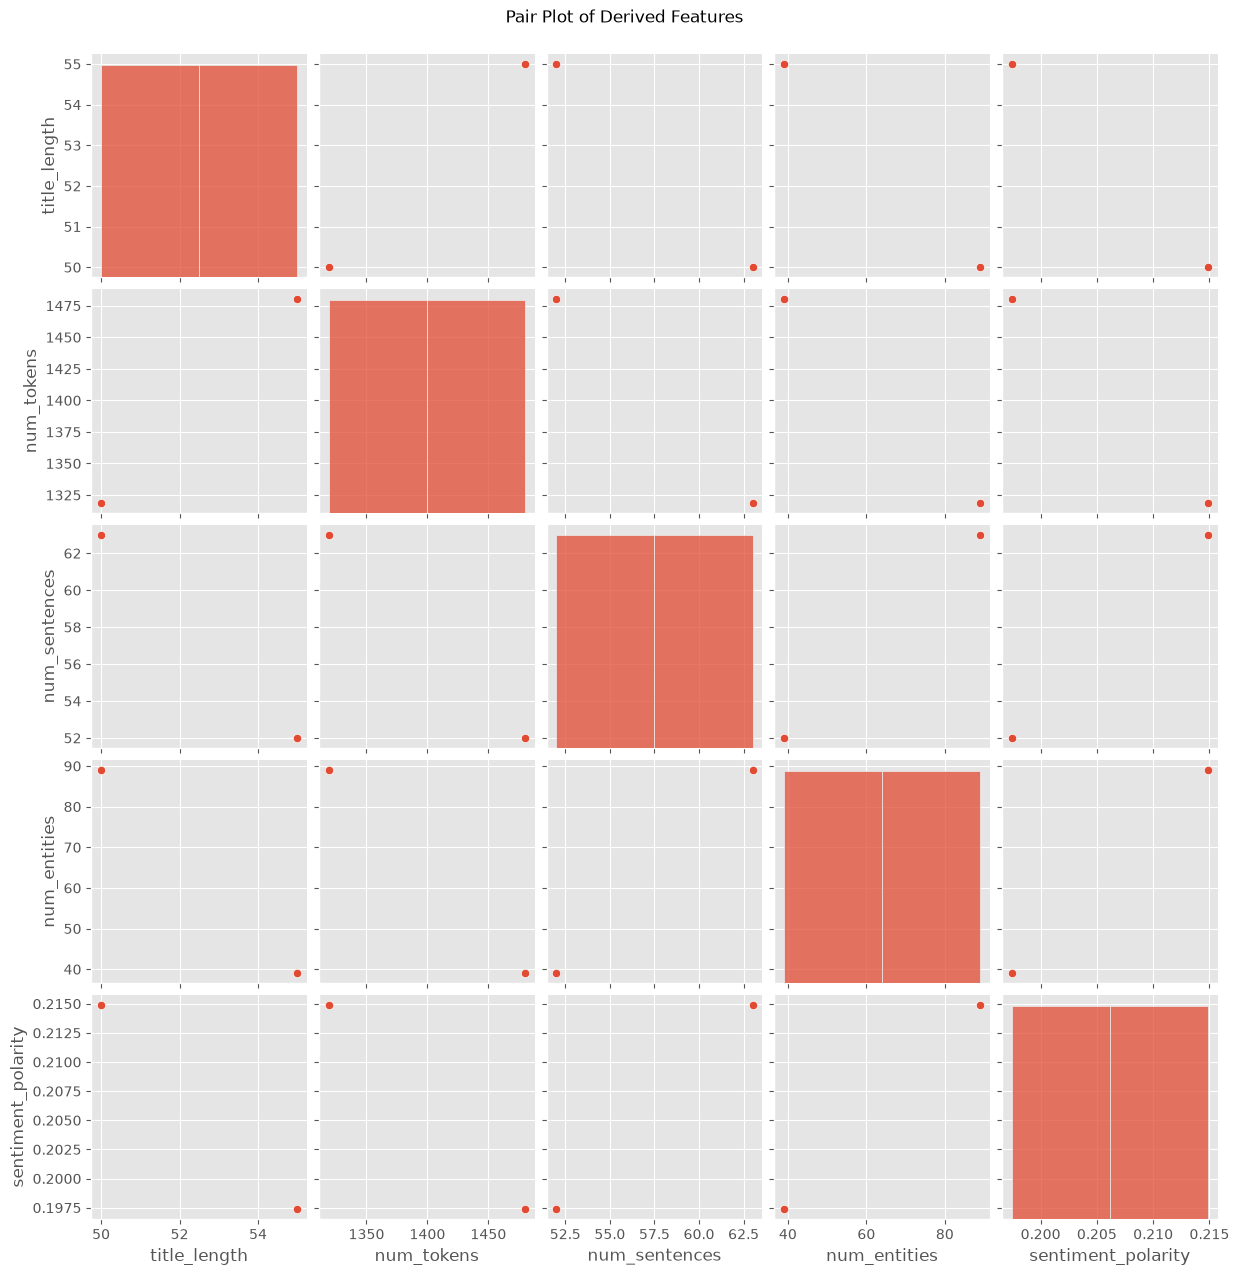

In [14]:
numeric_cols = [
    'title_length',
    'num_tokens',
    'num_sentences',
    'num_entities',
    'sentiment_polarity'
]

sns.pairplot(df[numeric_cols])
plt.suptitle('Pair Plot of Derived Features', y=1.02)
plt.show()

In [15]:
# The same information as numbers. With five articles this is indicative only.
print("Correlation matrix:\n")
display(df[numeric_cols].corr().round(2))

Correlation matrix:



,title_length,num_tokens,num_sentences,num_entities,sentiment_polarity
title_length,1.0,1.0,-1.0,-1.0,-1.0
num_tokens,1.0,1.0,-1.0,-1.0,-1.0
num_sentences,-1.0,-1.0,1.0,1.0,1.0
num_entities,-1.0,-1.0,1.0,1.0,1.0
sentiment_polarity,-1.0,-1.0,1.0,1.0,1.0


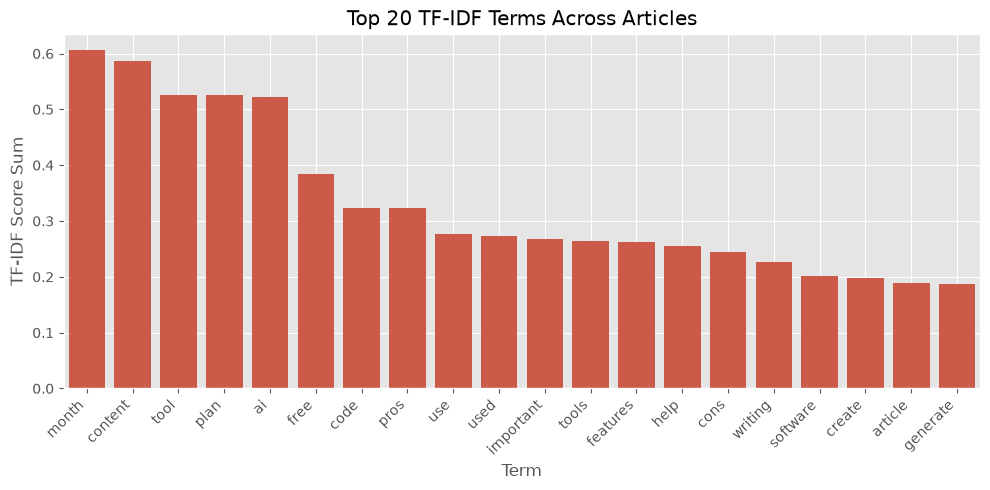

Sparse matrix shape (documents x terms): (2, 20)


In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

# stop_words='english' discards 'the', 'a', ...; max_features keeps the top 20
vectorizer = TfidfVectorizer(stop_words='english', max_features=20)

X = vectorizer.fit_transform(df['text'])
tfidf_df = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

# Sum each term's score across all documents to rank global importance
tfidf_sums = tfidf_df.sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=tfidf_sums.index, y=tfidf_sums.values)
plt.title("Top 20 TF-IDF Terms Across Articles")
plt.ylabel("TF-IDF Score Sum")
plt.xlabel("Term")
plt.xticks(rotation=45, ha='right')
plt.grid(True)
plt.tight_layout()
plt.show()

print("Sparse matrix shape (documents x terms):", X.shape)

In [17]:
import truststore
truststore.inject_into_ssl()   # remove if you are on a network without SSL inspection

import time
import requests
import pandas as pd
from bs4 import BeautifulSoup

urls = [
    # --- the original five ---
    'https://techncruncher.blogspot.com/2025/01/top-10-ai-tools-that-will-transform.html',
    'https://techncruncher.blogspot.com/2023/12/limewire-ai-studio-review-2023-details.html',
    'https://techncruncher.blogspot.com/2023/01/top-10-ai-tools-in-2023-that-will-make.html',
    'https://techncruncher.blogspot.com/2022/11/top-10-ai-content-generator-writer.html',
    'https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html',
    # --- Exercise 1: two URLs of my own ---
    'https://googleblog.blogspot.com/2015/08/google-alphabet.html',   # Blogger (expected to work)
    'https://en.wikipedia.org/wiki/Web_scraping',                     # Not Blogger (expected to fail)
]

headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
articles = []
failures = []   # (url, reason) pairs for the Exercise 1 report

for url in urls:
    try:
        res = requests.get(url, headers=headers, timeout=10)
        res.raise_for_status()
        soup = BeautifulSoup(res.content, 'lxml')

        title = soup.find('h3', class_='post-title')
        title = title.get_text(strip=True) if title else soup.title.get_text(strip=True)

        content_div = soup.find('div', class_='post-body entry-content')
        if not content_div:
            print(f"[SKIP] No content block found: {url}")
            failures.append((url, "selector div.post-body.entry-content not found"))
            continue

        paragraphs = content_div.find_all('p')
        text = ' '.join(p.get_text(strip=True) for p in paragraphs)

        if len(text) > 100:
            articles.append({'url': url, 'title': title, 'text': text})
        else:
            print(f"[SKIP] Too short ({len(text)} chars): {url}")
            failures.append((url, f"only {len(text)} chars of <p> text"))

        time.sleep(1)
    except Exception as e:
        print(f"[ERROR] {url} -> {e}")
        failures.append((url, f"request error: {type(e).__name__}"))

df = pd.DataFrame(articles)
print(f"\nScraped {len(df)} of {len(urls)} articles.")
df.head()

[SKIP] Too short (0 chars): https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html
[SKIP] No content block found: https://googleblog.blogspot.com/2015/08/google-alphabet.html
[SKIP] No content block found: https://en.wikipedia.org/wiki/Web_scraping

Scraped 4 of 7 articles.


,url,title,text
0,https://techncruncher.blogspot.com/2025/01/top...,Top 10 AI Tools That Will Transform Your Conte...,Looking to level up your content creation gam...
1,https://techncruncher.blogspot.com/2023/12/lim...,"LimeWire AI Studio Review 2023: Details, Prici...",In the rapidly advancing landscape of AI tech...
2,https://techncruncher.blogspot.com/2023/01/top...,Top 10 AI Tools in 2023 That Will Make Your Li...,"In this article, we explore the top 10 AI too..."
3,https://techncruncher.blogspot.com/2022/11/top...,Top 10 AI Content Generator & Writer Tools in ...,There are a number of different AI content ...


In [18]:
def diagnose(url):
    res = requests.get(url, headers=headers, timeout=10)
    soup = BeautifulSoup(res.content, 'lxml')

    print("=" * 80)
    print(url)
    print("HTTP status:", res.status_code)

    # Did the lab's selectors match?
    print("h3.post-title found          :", soup.find('h3', class_='post-title') is not None)
    print("div.post-body.entry-content  :", soup.find('div', class_='post-body entry-content') is not None)

    # What does the page use instead?
    candidates = soup.find_all(['div', 'article', 'main'], class_=True)
    classes = sorted({" ".join(c.get('class')) for c in candidates
                      if any(k in " ".join(c.get('class')).lower()
                             for k in ('post', 'entry', 'content', 'article', 'body'))})
    print("Content-like class names     :", classes[:12])
    print("<article> tags present       :", len(soup.find_all('article')))
    print("<p> tags on whole page       :", len(soup.find_all('p')))

for url, reason in failures:
    try:
        diagnose(url)
    except Exception as e:
        print(f"Could not diagnose {url}: {e}")

https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html
HTTP status: 200
h3.post-title found          : False
div.post-body.entry-content  : True
Content-like class names     : ['blog-post hentry item-post', 'blog-posts hfeed container item-post-wrap', 'comments-content', 'popular-post post gaint-post item0', 'popular-post post item1', 'popular-post post item2', 'popular-post post item3', 'post-body entry-content', 'post-footer', 'post-inner-area', 'post-inner-comments flex', 'post-inner-data flex']
<article> tags present       : 1
<p> tags on whole page       : 10
https://googleblog.blogspot.com/2015/08/google-alphabet.html
HTTP status: 200
h3.post-title found          : False
div.post-body.entry-content  : False
Content-like class names     : ['article-container__ai-box uni-grid__col--layout-6', 'article-share__title', 'copy-link__dialog copy-link__content', 'site-content', 'uni-article-card__content', 'uni-article-card__meta', 'uni-article-card__shape', 'uni-a

In [19]:
if not df.empty:
    df.to_csv("articles_raw.csv", index=False)
    print("Saved articles_raw.csv")
else:
    df = pd.read_csv("articles_raw.csv")
    print("Network scrape empty -- loaded the cached articles_raw.csv instead.")
print(df.shape)

Saved articles_raw.csv
(4, 3)
